# Single Layer Perceptron (SLP) — Klasifikasi Iris (Setosa vs Versicolor)
WHAT TO DO:
- Memakai 100 sampel pertama dataset Iris klasik: `Setosa` (label `0`) dan `Versicolor` (label `1`) — sama seperti sheet `Data`.
- Membangun Single Layer Perceptron dengan aktivasi **sigmoid**.
- Melatih dengan **gradient descent online (per-sampel)** pada loss **Sum Squared Error**, persis seperti update bobot baris-per-baris di sheet `SLP-Training`:
  - `z = bias + Σ wᵢ·xᵢ`
  - `ŷ = g(z) = 1 / (1 + e^-z)` (Sigmoid)
  - `error = ŷ - target`
  - `SSE = error²`
  - `gradient_i = 2·error·ŷ·(1-ŷ)·xᵢ` (angka `2` muncul dari turunan `error²`)
  - `wᵢ ← wᵢ - lr·gradient_i`
- Mengevaluasi ke set validation di setiap epoch (forward pass saja, tanpa update bobot), sama seperti sheet `SLP-Validation`.




In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

np.random.seed(0)
%matplotlib inline


## 1. Masukkan / muat datanya


In [ ]:
import os

DATA_PATH = "/content/Copy of PMM-TemplateSLP.xlsx"
SHEET_NAME = "Data"

if os.path.exists(DATA_PATH):
    # Sheet "Data" tidak punya header: X1, X2, X3, X4, Species
    raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME, header=None,
                         names=["X1", "X2", "X3", "X4", "Species"])
    raw = raw.dropna(subset=["X1"]).reset_index(drop=True)

    # Setosa = 0, Versicolor = 1 (seperti keterangan di sheet SLP-Training)
    label_map = {"Iris-setosa": 0, "Iris-versicolor": 1}
    raw = raw[raw["Species"].isin(label_map)].reset_index(drop=True)
    raw["TARGET"] = raw["Species"].map(label_map)

    X_all = raw[["X1", "X2", "X3", "X4"]].to_numpy(dtype=float)
    y_all = raw["TARGET"].to_numpy(dtype=int)

    df = raw[["X1", "X2", "X3", "X4", "TARGET"]]
    print(f"Data dimuat dari '{DATA_PATH}' — {len(df)} baris.")
else:
    from sklearn.datasets import load_iris
    iris = load_iris()
    X_all = iris.data[:100, :]
    y_all = iris.target[:100]
    df = pd.DataFrame(X_all, columns=["X1", "X2", "X3", "X4"])
    df["TARGET"] = y_all
    print(f"File '{DATA_PATH}' tidak ditemukan — pakai dataset Iris bawaan sklearn sebagai gantinya.")

df.head()


Data dimuat dari '/content/Copy of PMM-TemplateSLP.xlsx' — 100 baris.


,X1,X2,X3,X4,TARGET
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 2. Train / validation split

Sheet `SLP-Training` memakai 80 baris dengan indeks **`0–39` dan `50–89`** (bukan 0-79 berurutan — ada "lompatan" 10 baris), diproses berurutan. Sheet `SLP-Validation` memakai 20 baris sisanya: indeks **`40–49`** dan **`90–99`**.

Jadi splitnya **benar-benar terpisah** (tidak ada overlap) — 80 baris training dan 20 baris validation total 100, cocok dengan 100 baris di sheet `Data`.

In [ ]:
train_idx = list(range(0, 40)) + list(range(50, 90))
val_idx = list(range(40, 50)) + list(range(90, 100))

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

print(f"Training samples:   {len(X_train)}  (indeks 0-39 & 50-89, urutan asli)")
print(f"Validation samples: {len(X_val)}  (indeks 40-49 & 90-99)")


Training samples:   80  (indeks 0-39 & 50-89, urutan asli)
Validation samples: 20  (indeks 40-49 & 90-99)


## 3. Single Layer Perceptron

Semua bobot (bias & tiap `teta_i`) diinisialisasi **0.5**, learning rate **0.1** — sama seperti header sheet `SLP-Training`.

Update dilakukan **per sampel** (online/stochastic gradient descent), bukan sekali per epoch tapi sesuai pola update baris-per-baris di sheet.

In [ ]:
class SLP:
    def __init__(self, n_features, lr=0.1, init_weight=0.5):
        self.lr = lr
        self.bias = init_weight
        self.weights = np.full(n_features, init_weight, dtype=float)

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-z))

    def forward(self, x):
        z = self.bias + np.dot(self.weights, x)
        y_hat = self.sigmoid(z)
        return z, y_hat

    def train_step(self, x, target):
        """One online SGD update for a single sample. Returns (y_hat, prediction, error, sse)."""
        z, y_hat = self.forward(x)
        error = y_hat - target
        sse = error ** 2
        prediction = 1 if y_hat >= 0.5 else 0

        # gradient of SSE = error^2 w.r.t. each weight (chain rule through sigmoid)
        grad_common = 2 * error * y_hat * (1 - y_hat)
        d_bias = grad_common          # bias's "input" is 1
        d_weights = grad_common * x

        self.bias -= self.lr * d_bias
        self.weights -= self.lr * d_weights

        return y_hat, prediction, error, sse

    def evaluate(self, x, target):
        """Forward pass only — no weight update. Used for validation."""
        z, y_hat = self.forward(x)
        error = y_hat - target
        sse = error ** 2
        prediction = 1 if y_hat >= 0.5 else 0
        return y_hat, prediction, error, sse


## 4. Training loop

Tiap epoch: iterasi satu kali ke seluruh sampel training (update bobot tiap sampel), lalu forward-pass saja ke seluruh sampel validation. Accuracy & total SSE dicatat untuk keduanya, per epoch — sama seperti kolom-kolom di sheet `Results`.

In [ ]:
def run_slp(X_train, y_train, X_val, y_val, epochs=5, lr=0.1, init_weight=0.5, seed=None):
    model = SLP(n_features=X_train.shape[1], lr=lr, init_weight=init_weight)
    rng = np.random.default_rng(seed)
    results = []

    for epoch in range(1, epochs + 1):
        # --- training pass (weights updated per sample) ---
        order = np.arange(len(X_train))
        if seed is not None:
            rng.shuffle(order)  # set seed=None to keep the original row order (like the sheet)

        train_correct, train_sse_total = 0, 0.0
        for i in order:
            y_hat, pred, error, sse = model.train_step(X_train[i], y_train[i])
            train_correct += int(pred == y_train[i])
            train_sse_total += sse
        train_acc = train_correct / len(X_train)

        # --- validation pass (forward only) ---
        val_correct, val_sse_total = 0, 0.0
        for i in range(len(X_val)):
            y_hat, pred, error, sse = model.evaluate(X_val[i], y_val[i])
            val_correct += int(pred == y_val[i])
            val_sse_total += sse
        val_acc = val_correct / len(X_val)

        results.append({
            "Epoch": epoch,
            "Training Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Training SSE": train_sse_total,
            "Validation SSE": val_sse_total,
        })

    return model, pd.DataFrame(results)


# seed=None mempertahankan urutan sampel asli tiap epoch, sama seperti workbook.
# Isi seed dengan angka kalau mau urutan training diacak tiap epoch.
final_model, results_df = run_slp(
    X_train, y_train, X_val, y_val, epochs=5, lr=0.1, init_weight=0.5, seed=None
)

results_df


,Epoch,Training Accuracy,Validation Accuracy,Training SSE,Validation SSE
0,1,0.5250,0.50,35.991092,6.579023
1,2,0.9500,0.50,2.996153,4.945786
2,3,0.9750,0.50,1.949776,3.517833
3,4,0.9750,0.85,1.388576,2.387627
4,5,0.9875,1.00,1.019213,1.631627


## 5. Bobot akhir

In [ ]:
print(f"Final bias : {final_model.bias:.6f}")
for i, w in enumerate(final_model.weights, start=1):
    print(f"Final teta{i}: {w:.6f}")


Final bias : 0.257720
Final teta1: -0.241802
Final teta2: -0.416903
Final teta3: 1.122214
Final teta4: 0.824059


## 6. Kurva Accuracy dan SSE

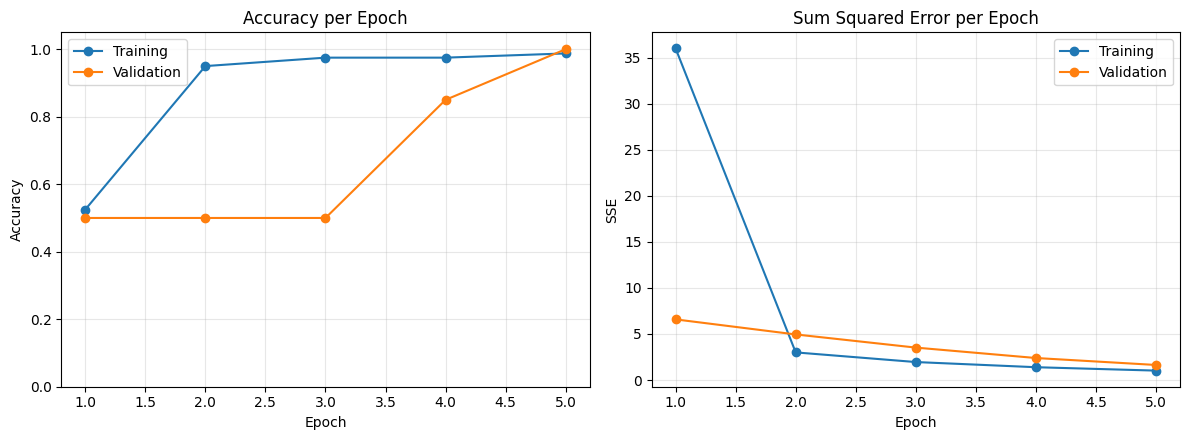

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(results_df["Epoch"], results_df["Training Accuracy"], marker="o", label="Training")
axes[0].plot(results_df["Epoch"], results_df["Validation Accuracy"], marker="o", label="Validation")
axes[0].set_title("Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(results_df["Epoch"], results_df["Training SSE"], marker="o", label="Training")
axes[1].plot(results_df["Epoch"], results_df["Validation SSE"], marker="o", label="Validation")
axes[1].set_title("Sum Squared Error per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("SSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Compare data excel dan python



In [ ]:
excel_results = pd.DataFrame({
    "Epoch": [1, 2, 3, 4, 5],
    "Training Accuracy": [0.525, 0.95, 0.975, 0.975, 0.9875],
    "Validation Accuracy": [0.5, 0.5, 0.5, 0.85, 1.0],
    "Training SSE": [35.9910924111623, 2.99615313824796, 1.9497755997115, 1.38857613427413, 1.01921265671413],
    "Validation SSE": [6.57902313109398, 4.94578646607125, 3.5178328133427, 2.38762746585947, 1.63162738822132],
})

comparison = results_df.merge(excel_results, on="Epoch", suffixes=(" (Python)", " (Excel)"))
comparison


,Epoch,Training Accuracy (Python),Validation Accuracy (Python),Training SSE (Python),Validation SSE (Python),Training Accuracy (Excel),Validation Accuracy (Excel),Training SSE (Excel),Validation SSE (Excel)
0,1,0.5250,0.50,35.991092,6.579023,0.5250,0.50,35.991092,6.579023
1,2,0.9500,0.50,2.996153,4.945786,0.9500,0.50,2.996153,4.945786
2,3,0.9750,0.50,1.949776,3.517833,0.9750,0.50,1.949776,3.517833
3,4,0.9750,0.85,1.388576,2.387627,0.9750,0.85,1.388576,2.387627
4,5,0.9875,1.00,1.019213,1.631627,0.9875,1.00,1.019213,1.631627
